# Movilidad urbana: exploración de viajes y oportunidades de análisis

Viajes del sistema público de bicicletas de Buenos Aires, 2024–2025. La exploración conecta calidad, comportamiento, territorio y decisiones de planificación.

Se leen los archivos completos y se conserva su contenido original. Las columnas derivadas y agregaciones se calculan en memoria para evaluar el modelo. La generación de tablas se implementa en `02_etl.ipynb`.

**Preguntas:** ¿qué explica la variación de actividad?, ¿cómo se organizan los flujos?, ¿qué estaciones presentan patrones direccionales persistentes?, ¿qué tan recurrente es el uso observado?, ¿qué contexto territorial y climático puede enriquecer las decisiones?

Ejecutar desde la raíz del caso o desde `notebooks/`. El proceso muestra avance por bloques y requiere memoria para aproximadamente 6,7 millones de registros compactos.

In [1]:
from pathlib import Path
from collections import Counter
import csv, gc, hashlib, io, json, platform, time, zipfile
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")
import matplotlib.pyplot as plt
from matplotlib.path import Path as Poligono
from IPython.display import display, JSON

RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "catalogos/FUENTES.json").is_file() and (p / "input").is_dir()), None)
if RAIZ is None:
    raise FileNotFoundError("Inicia Jupyter desde la raíz del caso o desde notebooks/.")
pd.set_option("display.max_rows", 15)
pd.set_option("display.max_columns", 12)
plt.rcParams.update({"figure.figsize": (10, 4), "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
AZUL, CELESTE = "#174A79", "#248CDD"
resultados = {}
display(pd.Series({"Python": platform.python_version(), "pandas": pd.__version__,
                   "numpy": np.__version__, "matplotlib": matplotlib.__version__}, name="Entorno"))

Python        3.14.6
pandas         3.0.3
numpy          2.4.6
matplotlib    3.11.0
Name: Entorno, dtype: str

## 1. Fuentes, integridad y alcance temporal

`catalogos/FUENTES.json` identifica descargas, fechas de consulta cuando están disponibles y huellas SHA-256. Los viajes son históricos; estaciones, barrios, ciclovías y subte son instantáneas de catálogo y su vigencia debe evaluarse por separado.

El clima procede de [Open-Meteo / ERA5](https://open-meteo.com/en/docs/historical-weather-api), un reanálisis meteorológico, consultado para el centro medio del catálogo de estaciones y el día local de Buenos Aires. El calendario es una compilación de fuentes oficiales citadas en cada fecha.

In [2]:
manifest = json.loads((RAIZ / "catalogos/FUENTES.json").read_text(encoding="utf-8"))
inventario = []
for fuente in manifest["fuentes"]:
    ruta = RAIZ / fuente["ruta"]
    with ruta.open("rb") as archivo:
        huella = hashlib.file_digest(archivo, "sha256").hexdigest()
    assert huella == fuente["sha256"], f"Cambió la fuente {ruta.name}"
    inventario.append({"Fuente": ruta.name, "MB": round(ruta.stat().st_size / 1e6, 2), "Integridad": "Coincide"})
display(pd.DataFrame(inventario))
estaciones = pd.read_csv(RAIZ / "catalogos/estaciones_bicicletas_fuente.csv")
assert estaciones.id.is_unique
resultados["fuentes_verificadas"] = len(inventario)

,Fuente,MB,Integridad
0,recorridos_2024.zip,176.29,Coincide
1,recorridos_2025.zip,207.75,Coincide
2,estaciones_bicicletas_fuente.csv,0.03,Coincide
3,ciclovias_fuente.geojson,0.96,Coincide
4,barrios_fuente.geojson,0.74,Coincide
5,estaciones_subte_fuente.geojson,0.02,Coincide
6,clima_diario_era5_fuente.json,0.02,Coincide
7,calendario_especial_2024_2025.csv,0.00,Coincide
8,usuarios_ecobici_2024.csv,7.28,Coincide
9,usuarios_ecobici_2025.csv,8.06,Coincide


## 2. Lectura completa y homologación para el análisis

Cambian `Id_recorrido` y `género` entre archivos. Los identificadores de 2025 incorporan el sufijo `BAEcobici`; los usuarios de 2024 pueden terminar en `.0`. Se admiten únicamente esas formas enteras explícitas. Los IDs que no cumplen la regla se marcan internamente con −1 y se cuentan como desconocidos.

La coma de `duracion_recorrido` en 2025 es separador de miles de segundos. Se conserva además la diferencia entre fechas para conciliar ambos campos. Las etiquetas de género y modelo se codifican para reducir memoria, conservando su diccionario.

Las huellas de fila solo sirven para localizar candidatos a duplicado. Si aparecen, debe compararse su contenido antes de retirarlos.

In [3]:
import os
carpeta_inicial = Path.cwd()
os.chdir(RAIZ)
%run src/01_Fuentes.ipynb
os.chdir(carpeta_inicial)

In [4]:
viajes, variantes, faltantes, esquemas, diccionarios = cargar_viajes(RAIZ)
display(pd.DataFrame(esquemas))

2024: 1,000,000 registros leídos
2024: 2,000,000 registros leídos
2024: 3,000,000 registros leídos
2024: lectura completa, 3,559,284 registros
2025: 1,000,000 registros leídos
2025: 2,000,000 registros leídos
2025: 3,000,000 registros leídos
2025: lectura completa, 3,156,182 registros
Lectura terminada en 183 s; memoria compacta: 698 MB


,Ano,Columnas,CSV
0,2024,17,badata_ecobici_recorridos_realizados_2024.csv
1,2025,17,Trips.csv


## 3. Identidad, duplicados y calidad por uso

Se comprueba la unicidad de viaje dentro de cada año y en toda la serie. La coincidencia de usuarios entre años es evidencia de solapamiento de códigos; no basta para confirmar continuidad de identidad. Los análisis de recurrencia se realizan por usuario y año.

Se distinguen registros observados, registros con duración positiva y registros con destino/fecha final válidos. Una anomalía de duración no elimina automáticamente evidencia de una salida.

In [5]:
viajes["Fecha"] = viajes.Inicio.dt.normalize()
viajes["Hora"] = viajes.Inicio.dt.hour.astype("int8")
viajes["DiaSemana"] = viajes.Inicio.dt.dayofweek.astype("int8")
delta = (viajes.Fin - viajes.Inicio).dt.total_seconds()
duplicado_ano = viajes.duplicated(["Ano","Viaje"], keep=False) & viajes.Viaje.ge(0)
duplicado_global = viajes.duplicated("Viaje", keep=False) & viajes.Viaje.ge(0)
resultados["identidad"] = {"filas":len(viajes), "ids_viaje_invalidos":int(viajes.Viaje.lt(0).sum()),
    "filas_id_repetido_ano":int(duplicado_ano.sum()), "filas_id_repetido_global":int(duplicado_global.sum()),
    "candidatos_fila_repetida":int(viajes.duplicated(["Ano","HuellaFila"]).sum())}
calidad = viajes.groupby("Ano").agg(Registros=("Viaje","size"), UsuariosCodigo=("Usuario","nunique"),
    Primera=("Inicio","min"), Ultima=("Inicio","max"), Dias=("Fecha","nunique"))
for etiqueta, mascara in {"DuracionNoPositiva":viajes.Segundos.le(0), "SinFin":viajes.Fin.isna(),
    "FinAnterior":delta.lt(0), "DesacuerdoDuracion1s":delta.sub(viajes.Segundos).abs().gt(1),
    "Mas24h":viajes.Segundos.gt(86400), "OrigenDesconocido":viajes.Origen.lt(0),
    "DestinoDesconocido":viajes.Destino.lt(0), "UsuarioDesconocido":viajes.Usuario.lt(0)}.items():
    calidad[etiqueta] = mascara.groupby(viajes.Ano).sum()
display(calidad)
display(pd.Series(resultados["identidad"]))
resultados["calidad"] = calidad.reset_index().assign(Primera=lambda x:x.Primera.astype(str), Ultima=lambda x:x.Ultima.astype(str)).to_dict("records")

,Registros,UsuariosCodigo,Primera,Ultima,Dias,DuracionNoPositiva,...,FinAnterior,DesacuerdoDuracion1s,Mas24h,OrigenDesconocido,DestinoDesconocido,UsuarioDesconocido
Ano,,,,,,,,,,,,,
2024,3559284,262673,2024-01-01 00:06:50,2024-12-31 23:58:25,366,37618,...,0,8,687,0,0,0
2025,3156182,286322,2025-01-01 00:01:40,2025-12-31 23:58:28,365,0,...,0,8,398,0,1,0


filas                       6715466
ids_viaje_invalidos               0
filas_id_repetido_ano             2
filas_id_repetido_global          2
candidatos_fila_repetida          1
dtype: int64

In [6]:
usuarios24 = np.unique(viajes.loc[(viajes.Ano==2024)&viajes.Usuario.ge(0),"Usuario"])
usuarios25 = np.unique(viajes.loc[(viajes.Ano==2025)&viajes.Usuario.ge(0),"Usuario"])
solapamiento = np.intersect1d(usuarios24, usuarios25).size
generos_usuario = viajes.loc[viajes.Usuario.ge(0)].groupby(["Ano","Usuario"]).Genero.nunique()
resultados["usuarios_identidad"] = {"codigos_2024":len(usuarios24), "codigos_2025":len(usuarios25),
    "codigos_compartidos":solapamiento, "usuario_ano_con_genero_variable":int(generos_usuario.gt(1).sum()),
    "alcance_cohortes":"Usuario dentro de cada año; continuidad interanual no acreditada"}
display(pd.Series(resultados["usuarios_identidad"]))
display(pd.DataFrame(faltantes).query("Nulos > 0"))
display(pd.DataFrame([{"Campo":k,"Etiqueta":v,"Codigo":c} for k,d in diccionarios.items() for v,c in d.items()]))

codigos_2024                                                                  262673
codigos_2025                                                                  286322
codigos_compartidos                                                           107243
usuario_ano_con_genero_variable                                                    0
alcance_cohortes                   Usuario dentro de cada año; continuidad intera...
dtype: object

,Ano,Campo,Nulos
8,2024,fecha_destino_recorrido,3379
16,2024,genero,11946
21,2025,nombre_estacion_origen,18
23,2025,long_estacion_origen,18
24,2025,lat_estacion_origen,18
26,2025,id_estacion_destino,1
27,2025,nombre_estacion_destino,29
28,2025,direccion_estacion_destino,177
29,2025,long_estacion_destino,29
30,2025,lat_estacion_destino,29


,Campo,Etiqueta,Codigo
0,Modelo,FIT,0
1,Modelo,ICONIC,1
2,Genero,MALE,0
3,Genero,FEMALE,1
4,Genero,OTHER,2
5,Genero,SIN DATO,3


In [7]:
sin_conflicto, replica_exacta, conflicto_id = resolver_replicas(RAIZ, viajes)
resultados["identidad"]["replicas_exactas_verificadas"]=int(replica_exacta.sum())
resultados["identidad"]["filas_conflicto_real"]=int(conflicto_id.sum())
observado = sin_conflicto & viajes.Inicio.notna() & viajes.Origen.ge(0)
completo = observado & viajes.Fin.notna() & delta.ge(0) & viajes.Destino.ge(0)
positivo = completo & viajes.Segundos.gt(0)
duracion_conciliada = positivo & delta.sub(viajes.Segundos).abs().le(1)
resultados["poblaciones"] = {"observados_sin_id_ambiguo":int(observado.sum()),
    "completos":int(completo.sum()), "completos_positivos":int(positivo.sum()),
    "duracion_conciliada":int(duracion_conciliada.sum())}
display(pd.Series(resultados["poblaciones"], name="Registros elegibles para cada uso"))
display(pd.crosstab(viajes.Ano, [viajes.Segundos.le(0),viajes.Origen.eq(viajes.Destino)],
                    rownames=["Año"], colnames=["Duración no positiva","Misma estación"]))
resultados["duracion_no_positiva_misma_estacion"] = int((viajes.Segundos.le(0)&viajes.Origen.eq(viajes.Destino)).sum())

observados_sin_id_ambiguo    6715465
completos                    6712085
completos_positivos          6677846
duracion_conciliada          6677830
Name: Registros elegibles para cada uso, dtype: int64

Duración no positiva    False          True       
Misma estación          False   True   False True 
Año                                               
2024                  3048550  473116  31407  6211
2025                  2880449  275733      0     0

## 4. Evolución, horarios y sensibilidad

El volumen observado incluye salidas con ID de viaje no ambiguo, fecha y origen válidos. La comparación de duración utiliza registros completos, positivos y conciliados. Se revisa si excluir extremos cambia la lectura, sin convertir un umbral exploratorio en una regla automática.

Ano,2024,2025,Variacion2025
Mes,,,
1,293151,301248,0.027621
2,276602,260340,-0.058792
3,313501,288796,-0.078804
4,281259,297754,0.058647
5,266596,230404,-0.135756
6,240287,150753,-0.372613
7,238055,177440,-0.254626
8,246193,227801,-0.074706
9,347735,289102,-0.168614


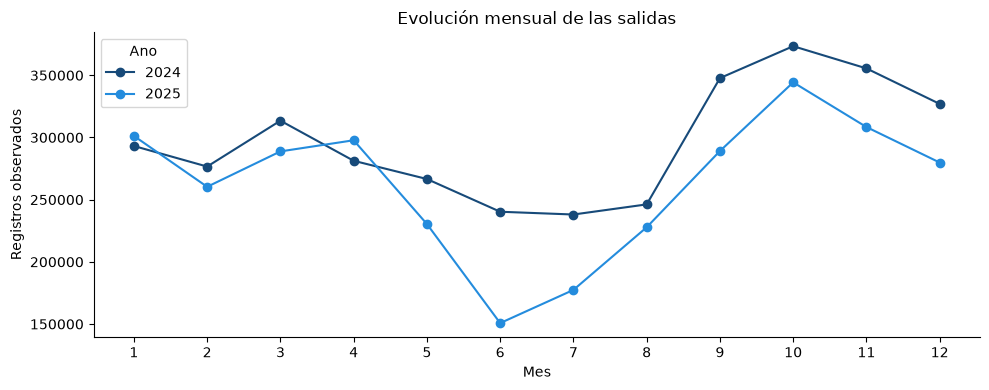

In [8]:
mensual = viajes.loc[observado].groupby(["Ano",viajes.Inicio.dt.month]).size().unstack(0)
mensual.index.name = "Mes"
mensual["Variacion2025"] = mensual[2025].div(mensual[2024]).sub(1)
display(mensual)
ax = mensual[[2024,2025]].plot(marker="o", color=[AZUL,CELESTE])
ax.set(ylabel="Registros observados", title="Evolución mensual de las salidas", xticks=range(1,13))
ax.ticklabel_format(axis="y", style="plain")
plt.tight_layout(); plt.show()
resultados["evolucion"] = {"registros_por_ano":viajes.loc[observado].groupby("Ano").size().to_dict(),
    "variacion_anual":float(mensual[2025].sum()/mensual[2024].sum()-1),
    "mes_mayor_caida":int(mensual.Variacion2025.idxmin()), "caida_mes":float(mensual.Variacion2025.min())}

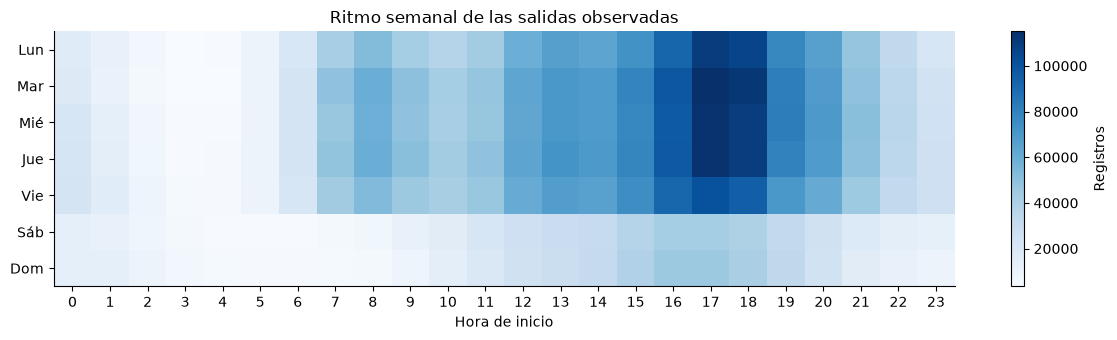

,Ano,Registros,MedianaMin,P95Min,P99Min,Mas2h,Mas24h
0,2024,3521657,14.833333,51.466667,99.633333,24051,687
1,2025,3156173,16.150000,55.450000,111.433333,27179,398


In [9]:
horario = viajes.loc[observado].groupby(["DiaSemana","Hora"]).size().unstack(fill_value=0).reindex(index=range(7), columns=range(24), fill_value=0)
fig, ax = plt.subplots(figsize=(12,3.5))
imagen = ax.imshow(horario, aspect="auto", cmap="Blues")
ax.set(xticks=range(24), yticks=range(7), yticklabels=["Lun","Mar","Mié","Jue","Vie","Sáb","Dom"],
       xlabel="Hora de inicio", title="Ritmo semanal de las salidas observadas")
fig.colorbar(imagen, ax=ax, label="Registros")
plt.tight_layout(); plt.show()
sensibilidad = []
for ano in (2024,2025):
    s = viajes.loc[duracion_conciliada & viajes.Ano.eq(ano),"Segundos"]
    sensibilidad.append({"Ano":ano,"Registros":len(s),"MedianaMin":s.median()/60,"P95Min":s.quantile(.95)/60,
        "P99Min":s.quantile(.99)/60,"Mas2h":int(s.gt(7200).sum()),"Mas24h":int(s.gt(86400).sum())})
display(pd.DataFrame(sensibilidad))
resultados["duraciones"] = sensibilidad

## 5. Identidad y ubicación histórica de estaciones

El enlace correcto usa el ID interno, no el número público incluido en algunos nombres. Se comparan coordenadas observadas entre años y contra el catálogo. Un desplazamiento mayor de 100 m localiza casos a investigar; no demuestra por sí solo una reubicación real.

Las variantes de coordenadas y nombres proceden de ambos extremos de los viajes. Su conteo representa eventos de estación, no viajes únicos.

In [10]:
def distancia_m(lon1, lat1, lon2, lat2):
    lon1,lat1,lon2,lat2 = np.radians([lon1,lat1,lon2,lat2])
    a = np.sin((lat2-lat1)/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2
    return 6371008.8 * 2 * np.arcsin(np.sqrt(np.clip(a,0,1)))

dominantes = variantes.loc[~(variantes.Lon.eq(0)&variantes.Lat.eq(0))].sort_values("Eventos", ascending=False).drop_duplicates(["Ano","Estacion"])
enlace = dominantes.merge(estaciones[["id","longitud","latitud"]], left_on="Estacion", right_on="id", how="left", validate="many_to_one")
enlace["DistanciaCatalogoM"] = distancia_m(enlace.Lon.to_numpy(), enlace.Lat.to_numpy(), enlace.longitud.to_numpy(), enlace.latitud.to_numpy())
comparacion = dominantes.pivot(index="Estacion", columns="Ano", values=["Lon","Lat"])
comparacion["DesplazamientoM"] = distancia_m(comparacion["Lon"][2024].to_numpy(),comparacion["Lat"][2024].to_numpy(),
                                             comparacion["Lon"][2025].to_numpy(),comparacion["Lat"][2025].to_numpy())
resultados["estaciones_historicas"] = {"ids_observados":int(dominantes.Estacion.nunique()),
    "estacion_ano_fuera_catalogo":int(enlace.id.isna().sum()),
    "estacion_ano_distinta_catalogo_100m":int(enlace.DistanciaCatalogoM.gt(100).sum()),
    "ids_desplazamiento_entre_anos_100m":int(comparacion["DesplazamientoM"].gt(100).sum())}
display(pd.Series(resultados["estaciones_historicas"]))
display(enlace.loc[enlace.DistanciaCatalogoM.gt(100),["Ano","Estacion","Nombre","DistanciaCatalogoM"]].sort_values("DistanciaCatalogoM",ascending=False).head(10))

ids_observados                         414
estacion_ano_fuera_catalogo             16
estacion_ano_distinta_catalogo_100m      7
ids_desplazamiento_entre_anos_100m       6
dtype: int64

,Ano,Estacion,Nombre,DistanciaCatalogoM
720,2025,583,357 - ATAHUALPA,615.626850
192,2025,177,177 -PLANETARIO,327.541942
690,2025,45,045 - Uruguay,269.550212
405,2025,212,129 - Velasco,219.310771
445,2024,368,378 - AGRONOMIA,218.929506
621,2025,420,375 - Ciudad Universitaria I,160.584064
442,2025,166,166 - Cementerio de Recoleta,131.672027


In [11]:
dispersion = []
for (ano, estacion), grupo in variantes.loc[~(variantes.Lon.eq(0)&variantes.Lat.eq(0))].dropna(subset=["Lon","Lat"]).groupby(["Ano","Estacion"]):
    base = grupo.loc[grupo.Eventos.idxmax()]
    dist = distancia_m(grupo.Lon.to_numpy(),grupo.Lat.to_numpy(),np.full(len(grupo),base.Lon),np.full(len(grupo),base.Lat))
    dispersion.append({"Ano":ano,"Estacion":estacion,"Variantes":len(grupo),"MaxM":float(dist.max()),
                       "EventosFuera100m":int(grupo.loc[dist>100,"Eventos"].sum())})
dispersion = pd.DataFrame(dispersion)
resultados["estaciones_historicas"]["estacion_ano_variantes_mas100m"] = int(dispersion.MaxM.gt(100).sum())
display(dispersion.query("MaxM > 100").sort_values("MaxM",ascending=False).head(10))
for rol in ("Origen","Destino"):
    cobertura = viajes[rol].isin(estaciones.id).groupby(viajes.Ano).mean()
    display(cobertura.rename(f"CoberturaID{rol}"))

,Ano,Estacion,Variantes,MaxM,EventosFuera100m
594,2025,307,2,3632.604121,82
793,2025,586,3,1259.226201,331
647,2025,407,3,665.220438,1748
790,2025,583,2,615.646029,693
513,2025,177,2,327.541942,2724
425,2025,45,2,269.606626,1578
538,2025,212,2,219.310771,12449
624,2025,368,4,218.935164,708
492,2025,150,2,213.764698,2014
504,2025,166,3,211.251191,11390


Ano
2024    0.988196
2025    0.998382
Name: CoberturaIDOrigen, dtype: float64

Ano
2024    0.987982
2025    0.998235
Name: CoberturaIDDestino, dtype: float64

## 6. Territorio e infraestructura

Barrio y comuna se derivan de polígonos oficiales. Los puntos no asignables o ambiguos se conservan como excepciones. Las distancias a subte son geodésicas; las distancias a segmentos de ciclovía utilizan una aproximación plana local para explorar sensibilidad. El ETL calcula las distancias a segmentos en EPSG:32721 y contrasta la proyección con geodesia WGS84.

Las proximidades describen el catálogo actual y no acreditan infraestructura disponible en 2024–2025 ni transbordos realizados.

In [12]:
barrios = json.loads((RAIZ/"catalogos/barrios_fuente.geojson").read_text(encoding="utf-8"))
def asignar_barrios(puntos):
    nombres = np.full(len(puntos), "Sin asignar", dtype=object)
    comunas = np.full(len(puntos), "Sin asignar", dtype=object)
    cuenta = np.zeros(len(puntos),dtype=int)
    for f in barrios["features"]:
        g = f["geometry"]
        poligonos = [g["coordinates"]] if g["type"]=="Polygon" else g["coordinates"]
        dentro = np.zeros(len(puntos), dtype=bool)
        for anillos in poligonos:
            pertenece = Poligono(anillos[0]).contains_points(puntos)
            for hueco in anillos[1:]: pertenece &= ~Poligono(hueco).contains_points(puntos)
            dentro |= pertenece
        cuenta += dentro
        nombres[dentro] = f["properties"]["nombre"]
        comunas[dentro] = str(f["properties"]["comuna"])
    nombres[cuenta!=1] = "Sin asignación única"
    comunas[cuenta!=1] = "Sin asignación única"
    return nombres, comunas, cuenta

puntos = estaciones[["longitud","latitud"]].to_numpy(dtype=float)
estaciones["BarrioDerivado"],estaciones["ComunaDerivada"],cuenta = asignar_barrios(puntos)
dominantes["BarrioObservado"],dominantes["ComunaObservada"],_ = asignar_barrios(dominantes[["Lon","Lat"]].to_numpy(dtype=float))
resultados["territorio"] = {"estaciones_catalogo":len(estaciones),"asignacion_unica":int((cuenta==1).sum()),
    "sin_asignacion":int((cuenta==0).sum()),"ambiguas":int((cuenta>1).sum())}
display(pd.Series(resultados["territorio"]))

estaciones_catalogo    407
asignacion_unica       405
sin_asignacion           2
ambiguas                 0
dtype: int64

In [13]:
subte = json.loads((RAIZ/"catalogos/estaciones_subte_fuente.geojson").read_text(encoding="utf-8"))
nodos = np.array([f["geometry"]["coordinates"] for f in subte["features"]], dtype=float)
dist_subte = np.vstack([distancia_m(np.full(len(nodos),lon),np.full(len(nodos),lat),nodos[:,0],nodos[:,1]) for lon,lat in puntos])
estaciones["DistanciaSubteM"] = dist_subte.min(axis=1)
ciclovias = json.loads((RAIZ/"catalogos/ciclovias_fuente.geojson").read_text(encoding="utf-8"))
escala = np.array([111195*np.cos(np.radians(puntos[:,1].mean())),111195])
lineas = [np.array(f["geometry"]["coordinates"])*escala for f in ciclovias["features"]]
inicio_seg = np.concatenate([x[:-1] for x in lineas]); fin_seg = np.concatenate([x[1:] for x in lineas])
vector = fin_seg-inicio_seg; norma = (vector*vector).sum(axis=1)
distancias = []
for p in puntos*escala:
    t = np.divide(((p-inicio_seg)*vector).sum(axis=1),norma,out=np.zeros_like(norma),where=norma>0).clip(0,1)
    distancias.append(float(np.linalg.norm(p-(inicio_seg+t[:,None]*vector),axis=1).min()))
estaciones["DistanciaCicloviaAproxM"] = distancias
resultados["conectividad_actual"] = {"puntos_subte":len(nodos),
    "estaciones_subte_300m":int(estaciones.DistanciaSubteM.le(300).sum()),
    "estaciones_subte_500m":int(estaciones.DistanciaSubteM.le(500).sum()),
    "estaciones_subte_750m":int(estaciones.DistanciaSubteM.le(750).sum()),
    "estaciones_ciclovia_100m_aprox":int(estaciones.DistanciaCicloviaAproxM.le(100).sum())}
display(pd.Series(resultados["conectividad_actual"]))

puntos_subte                       90
estaciones_subte_300m              85
estaciones_subte_500m             141
estaciones_subte_750m             192
estaciones_ciclovia_100m_aprox    198
dtype: int64

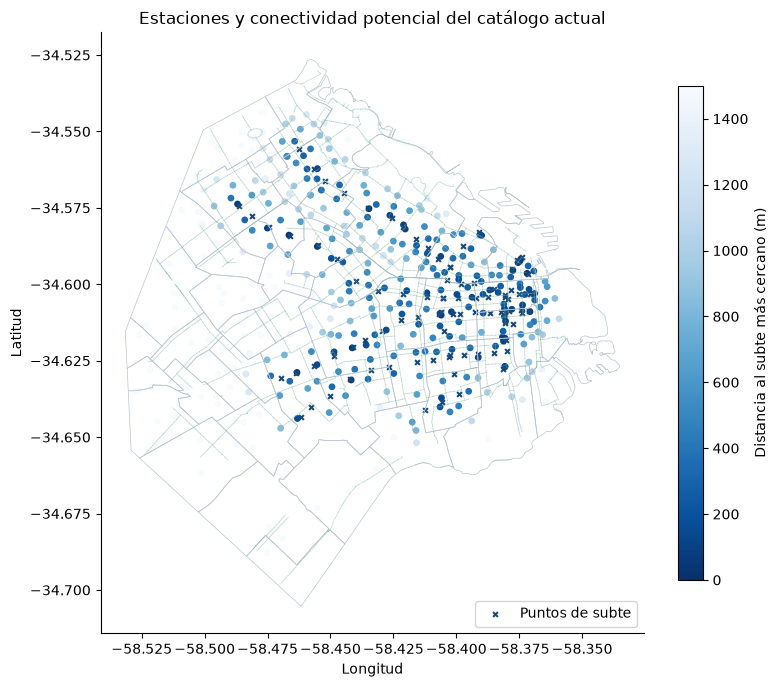

In [14]:
fig,ax = plt.subplots(figsize=(8,8))
for f in barrios["features"]:
    g=f["geometry"]; poligonos=[g["coordinates"]] if g["type"]=="Polygon" else g["coordinates"]
    for anillos in poligonos:
        xy=np.array(anillos[0]); ax.plot(xy[:,0],xy[:,1],color="#B9C6D2",linewidth=.5)
for f in ciclovias["features"]:
    xy=np.array(f["geometry"]["coordinates"]); ax.plot(xy[:,0],xy[:,1],color="#7DB9A0",alpha=.4,linewidth=.6)
marca=ax.scatter(puntos[:,0],puntos[:,1],c=estaciones.DistanciaSubteM,s=15,cmap="Blues_r",vmin=0,vmax=1500)
ax.scatter(nodos[:,0],nodos[:,1],marker="x",s=12,color=AZUL,label="Puntos de subte")
ax.set(title="Estaciones y conectividad potencial del catálogo actual",xlabel="Longitud",ylabel="Latitud")
ax.set_aspect(1/np.cos(np.radians(puntos[:,1].mean())))
fig.colorbar(marca,ax=ax,label="Distancia al subte más cercano (m)",shrink=.65)
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

## 7. Flujos, distancia entre extremos y papel de las estaciones

Se exploran registros completos y positivos. La distancia geodésica es una separación entre extremos; un viaje que regresa a la misma estación puede haber recorrido una ruta larga. La razón distancia/tiempo solo sirve como diagnóstico.

Las llegadas se agregan con fecha y hora de destino, y las salidas con fecha y hora de origen. El saldo describe movimientos registrados; no representa inventario, disponibilidad o capacidad.

In [15]:
flujo = viajes.loc[positivo].groupby(["Ano","Origen","Destino"]).size().rename("Viajes").reset_index()
concentracion = []
for ano,g in flujo.groupby("Ano"):
    concentracion.append({"Ano":int(ano),"ParesOD":len(g),"ParticipacionTop20":float(g.Viajes.nlargest(20).sum()/g.Viajes.sum()),
        "MismaEstacion":int(g.loc[g.Origen.eq(g.Destino),"Viajes"].sum())})
distancia = distancia_m(viajes.LonO.to_numpy(),viajes.LatO.to_numpy(),viajes.LonD.to_numpy(),viajes.LatD.to_numpy())/1000
geo_valida = ~(viajes.LonO.eq(0)&viajes.LatO.eq(0))&~(viajes.LonD.eq(0)&viajes.LatD.eq(0))&np.isfinite(distancia)&viajes.LatO.between(-90,90)&viajes.LatD.between(-90,90)&viajes.LonO.between(-180,180)&viajes.LonD.between(-180,180)
velocidad_recta = np.divide(distancia,viajes.Segundos.to_numpy()/3600,out=np.full(len(viajes),np.nan),where=viajes.Segundos.to_numpy()>0)
resultados["flujos"] = concentracion
resultados["distancia"] = {"registros_positivos_con_coordenadas":int((positivo&geo_valida).sum()),
    "mediana_recta_km":float(np.median(distancia[positivo&geo_valida])),
    "razon_recta_tiempo_mas60kmh":int((positivo&geo_valida&(velocidad_recta>60)).sum())}
display(pd.DataFrame(concentracion)); display(pd.Series(resultados["distancia"]))
display(flujo.sort_values("Viajes",ascending=False).head(10))

,Ano,ParesOD,ParticipacionTop20,MismaEstacion
0,2024,90451,0.026082,473116
1,2025,95496,0.019770,275733


registros_positivos_con_coordenadas    6.677624e+06
mediana_recta_km                       1.667084e+00
razon_recta_tiempo_mas60kmh            6.057100e+04
dtype: float64

,Ano,Origen,Destino,Viajes
80579,2024,516,516,8076
80251,2024,515,515,7754
26141,2024,152,152,7281
754,2024,5,5,6611
116143,2025,152,152,6206
2748,2024,14,14,5118
170250,2025,515,515,5002
35947,2024,202,202,4845
69824,2024,458,458,4831
93470,2025,14,516,4567


In [16]:
salidas = viajes.loc[positivo].groupby(["Origen","Fecha","Hora"]).size().rename("Salidas")
llegadas = viajes.loc[positivo].groupby(["Destino",viajes.Fin.dt.normalize(),viajes.Fin.dt.hour]).size().rename("Llegadas")
salidas.index.names = llegadas.index.names = ["Estacion","Fecha","Hora"]
movimientos = pd.concat([salidas,llegadas],axis=1).fillna(0).astype("int32").reset_index()
assert movimientos.Salidas.sum()==movimientos.Llegadas.sum()==positivo.sum()
movimientos["Saldo"] = movimientos.Llegadas-movimientos.Salidas
movimientos["Eventos"] = movimientos.Llegadas+movimientos.Salidas
movimientos["Ano"] = movimientos.Fecha.dt.year
manana = movimientos.loc[movimientos.Hora.between(7,9)&movimientos.Fecha.dt.dayofweek.lt(5)]
perfil = manana.groupby(["Ano","Estacion"])[["Salidas","Llegadas","Eventos","Saldo"]].sum()
perfil["Desequilibrio"] = perfil.Saldo.abs()/perfil.Eventos
destinos = flujo.groupby(["Ano","Origen"]).Destino.nunique().rename("DestinosDistintos")
destinos.index.names=["Ano","Estacion"]
perfil = perfil.join(destinos,validate="one_to_one")
assert len(perfil)<=2*viajes.Origen.nunique()
display(perfil.sort_values("Eventos",ascending=False).head(10))
resultados["movimientos"] = {"filas_agregadas_estacion_fecha_hora":len(movimientos),
    "salidas":int(movimientos.Salidas.sum()),"llegadas":int(movimientos.Llegadas.sum()),
    "perfil_manana_ano_estacion":len(perfil)}

Salidas  Llegadas  Eventos  Saldo  Desequilibrio  \
Ano  Estacion                                                     
2024 130          7418      3352    10770  -4066       0.377530   
     175          7832      2737    10569  -5095       0.482070   
     4            4177      3989     8166   -188       0.023022   
     444          3679      3828     7507    149       0.019848   
2025 130          5132      2365     7497  -2767       0.369081   
2024 14           4155      2758     6913  -1397       0.202083   
     8            3196      3636     6832    440       0.064403   
     3            2515      3983     6498   1468       0.225916   
     150          3242      3223     6465    -19       0.002939   
2025 175          5229      1131     6360  -4098       0.644340   

               DestinosDistintos  
Ano  Estacion                     
2024 130                   281.0  
     175                   293.0  
     4                     248.0  
     444                   243.0  
2025 130                   288.0  
2024 14                    351.0  
     8                     309.0  
     3                     247.0  
     150                   188.0  
2025 175                   280.0

In [17]:
estabilidad = manana.assign(Mes=manana.Fecha.dt.to_period("M").astype(str)).groupby(["Ano","Estacion","Mes"])[["Saldo","Eventos"]].sum().reset_index()
estabilidad["Signo"] = np.sign(estabilidad.Saldo)
persistencia = estabilidad.groupby(["Ano","Estacion"]).agg(Meses=("Mes","nunique"),
    Persistencia=("Signo",lambda x:max((x>0).sum(),(x<0).sum())/len(x)))
perfil = perfil.join(persistencia,validate="one_to_one")
base_prioridad = perfil.loc[perfil.Meses.ge(6)].copy()
for campo in ("Eventos","Desequilibrio","Persistencia"):
    base_prioridad[campo+"Rango"] = base_prioridad.groupby(level="Ano")[campo].rank(pct=True)
for nombre,pesos in {"Volumen":(.6,.2,.2),"Direccion":(.2,.6,.2),"Persistencia":(.2,.2,.6)}.items():
    base_prioridad["Indice"+nombre] = sum(p*base_prioridad[c+"Rango"] for p,c in zip(pesos,("Eventos","Desequilibrio","Persistencia")))
top = {n:set(base_prioridad.xs(2025).nlargest(20,"Indice"+n).index) for n in ("Volumen","Direccion","Persistencia")}
resultados["prioridades"] = {"candidatos_ano_estacion":len(base_prioridad),
    "comunes_top20_tres_criterios_2025":len(set.intersection(*top.values())),
    "regla":"Exploración: 6 meses observados, mañana laboral 07–09 h, rangos por año; no ranking de inversión"}
display(pd.Series(resultados["prioridades"]))
display(base_prioridad.xs(2025).nlargest(10,"IndiceVolumen")[["Eventos","Desequilibrio","Persistencia","IndiceVolumen","IndiceDireccion"]])

candidatos_ano_estacion                                                            765
comunes_top20_tres_criterios_2025                                                   13
regla                                Exploración: 6 meses observados, mañana labora...
dtype: object

,Eventos,Desequilibrio,Persistencia,IndiceVolumen,IndiceDireccion
Estacion,,,,,
175,6360,0.644340,1.0,0.961097,0.956110
26,5236,0.626050,1.0,0.952618,0.950623
353,4898,0.673744,1.0,0.947132,0.954115
130,7497,0.369081,1.0,0.945137,0.904239
111,3800,0.509474,1.0,0.927681,0.927681
35,5036,0.340747,1.0,0.925686,0.877805
152,5459,0.294743,1.0,0.918204,0.839401
435,3217,0.445446,1.0,0.906234,0.911222
2,3123,0.388409,1.0,0.897257,0.896259


## 8. Usuarios, frecuencia y cohortes observadas

Se utilizan salidas con duración positiva, destino completo e ID de usuario válido, identificando al usuario dentro de cada año. Primera observación anual no equivale a registro real.

Retorno 30: al menos un viaje en un día posterior al primero, hasta 30 días después inclusive. Retorno 90 amplía la ventana a 90 días. Se incluyen en cada denominador únicamente usuarios cuya ventana completa cabe dentro del año disponible. La recurrencia del mismo día se estudia por separado.

Los atributos del cierre anual describen el periodo observado. No deben utilizarse como predictores de un resultado ocurrido antes de ese cierre.

In [18]:
base_usuarios = positivo & viajes.Usuario.ge(0)
usuarios = viajes.loc[base_usuarios].groupby(["Ano","Usuario"]).agg(Primera=("Fecha","min"),
    Ultima=("Fecha","max"),Viajes=("Viaje","size"),DiasActivos=("Fecha","nunique"),
    EstacionesOrigen=("Origen","nunique"))
resumen_usuarios = usuarios.groupby(level="Ano").agg(Usuarios=("Viajes","size"),Viajes=("Viajes","sum"),
    MedianaViajes=("Viajes","median"),MedianaDias=("DiasActivos","median"))
resumen_usuarios["ViajesPorUsuario"] = resumen_usuarios.Viajes/resumen_usuarios.Usuarios
resumen_usuarios["UnSoloDia"] = usuarios.DiasActivos.eq(1).groupby(level="Ano").mean()
display(resumen_usuarios)
resultados["usuarios"] = resumen_usuarios.reset_index().to_dict("records")
dias_usuario = viajes.loc[base_usuarios,["Ano","Usuario","Fecha"]].drop_duplicates()
dias_usuario = dias_usuario.join(usuarios.Primera, on=["Ano","Usuario"],validate="many_to_one")
dias_usuario["DiasDesdePrimera"] = (dias_usuario.Fecha-dias_usuario.Primera).dt.days
usuarios["Cohorte"] = usuarios.Primera.dt.to_period("M").astype(str)
cierre_por_ano = viajes.groupby("Ano").Fecha.max()
usuarios["Cierre"] = usuarios.index.get_level_values("Ano").map(cierre_por_ano)
usuarios["RecenciaCierreDias"] = (usuarios.Cierre-usuarios.Ultima).dt.days

,Usuarios,Viajes,MedianaViajes,MedianaDias,ViajesPorUsuario,UnSoloDia
Ano,,,,,,
2024,261432,3521665,3.0,2.0,13.470673,0.383878
2025,286322,3156181,3.0,2.0,11.023187,0.410255


Elegibles  Retornaron      Tasa
Ano  Ventana                                 
2024 30          243421      120101  0.493388
     90          203223      120938  0.595100
     180         153723      102945  0.669679
2025 30          269489      123637  0.458783
     90          228061      128284  0.562499
     180         175244      112681  0.642995

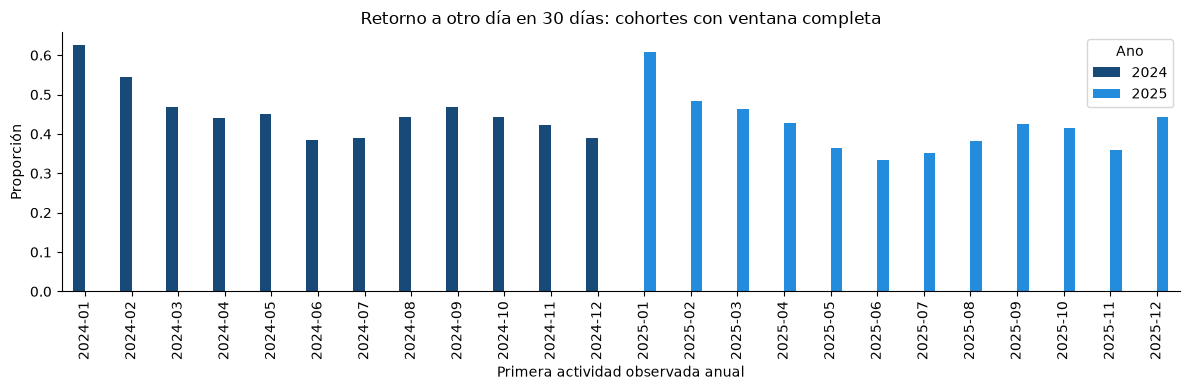

In [19]:
cohortes = []
for ventana in (30,90,180):
    retorno = dias_usuario.loc[dias_usuario.DiasDesdePrimera.between(1,ventana)].groupby(["Ano","Usuario"]).size().gt(0)
    usuarios[f"Elegible{ventana}"] = (usuarios.Cierre-usuarios.Primera).dt.days.ge(ventana)
    usuarios[f"Retorno{ventana}"] = retorno.reindex(usuarios.index,fill_value=False)
    elegibles = usuarios.loc[usuarios[f"Elegible{ventana}"]]
    tabla = elegibles.groupby(["Ano","Cohorte"]).agg(Elegibles=("Viajes","size"),Retornaron=(f"Retorno{ventana}","sum")).reset_index()
    tabla["Ventana"] = ventana; tabla["Tasa"] = tabla.Retornaron/tabla.Elegibles
    cohortes.append(tabla)
cohortes = pd.concat(cohortes,ignore_index=True)
retornos = cohortes.groupby(["Ano","Ventana"])[["Elegibles","Retornaron"]].sum()
retornos["Tasa"] = retornos.Retornaron/retornos.Elegibles
display(retornos)
resultados["retornos"] = retornos.reset_index().to_dict("records")
grafico = cohortes.query("Ventana==30").pivot(index="Cohorte",columns="Ano",values="Tasa")
ax=grafico.plot.bar(color=[AZUL,CELESTE],figsize=(12,4))
ax.set(title="Retorno a otro día en 30 días: cohortes con ventana completa",ylabel="Proporción",xlabel="Primera actividad observada anual")
plt.tight_layout(); plt.show()
del dias_usuario
_ = gc.collect()

In [20]:
descomposicion = resumen_usuarios[["Usuarios","ViajesPorUsuario","Viajes"]]
u24,u25 = descomposicion.loc[2024,"Usuarios"],descomposicion.loc[2025,"Usuarios"]
f24,f25 = descomposicion.loc[2024,"ViajesPorUsuario"],descomposicion.loc[2025,"ViajesPorUsuario"]
efecto_usuarios = (u25-u24)*(f24+f25)/2
efecto_frecuencia = (f25-f24)*(u24+u25)/2
cambio = descomposicion.loc[2025,"Viajes"]-descomposicion.loc[2024,"Viajes"]
assert np.isclose(efecto_usuarios+efecto_frecuencia,cambio)
resultados["descomposicion"] = {"cambio_viajes":float(cambio),"componente_usuarios":float(efecto_usuarios),
    "componente_frecuencia":float(efecto_frecuencia),"metodo":"Descomposición simétrica de V=U×F; descriptiva"}
display(pd.Series(resultados["descomposicion"]))

cambio_viajes                                                 -365484.0
componente_usuarios                                       304826.090725
componente_frecuencia                                    -670310.090725
metodo                   Descomposición simétrica de V=U×F; descriptiva
dtype: object

## 9. Altas reales y activación

Los catálogos oficiales de altas 2024 y 2025 permiten distinguir registro real de primera actividad observada. Su población corresponde a las altas de esos años; no representa todos los usuarios que viajaron. La [fuente de 2025](https://data.buenosaires.gob.ar/dataset/bicicletas-publicas/resource/f522cefa-d113-4871-bb0f-559ccfdbd639) incluye el indicador administrativo `Customer Has Dni (Yes / No)`; el perfil analítico utiliza fecha de alta, edad y género.

Activación en N días: primer viaje completo y positivo observado entre la fecha de alta y N días después, ambos inclusive. Se usan días de calendario. El denominador conserva las altas sin viaje, exige una ventana completa dentro del año y excluye identidades ambiguas o cronología contradictoria. Las altas sin viaje se conservan sin activación observada.

La edad es la reportada en el catálogo, con fecha de referencia no acreditada. Se distinguen edades fuera de 0–120 como anomalías de plausibilidad; los valores fuera de plausibilidad permanecen reportados y sin segmentación etaria. La segmentación es descriptiva de las altas con dato utilizable.

In [21]:
altas_anuales=[]
for ano in (2024,2025):
    a=pd.read_csv(RAIZ/f"catalogos/usuarios_ecobici_{ano}.csv",dtype="string",encoding="utf-8-sig")
    a["Usuario"]=ids_enteros(a.iloc[:,0])
    a["Ano"]=ano
    a["FechaAlta"]=pd.to_datetime(a.fecha_alta,errors="coerce")
    a["EdadReportada"]=pd.to_numeric(a.edad_usuario,errors="coerce")
    altas_anuales.append(a[["Ano","Usuario","FechaAlta","EdadReportada"]])
altas=pd.concat(altas_anuales,ignore_index=True)
altas["IdentidadAmbigua"]=altas.duplicated(["Ano","Usuario"],keep=False)|altas.Usuario.lt(0)
activacion=altas.join(usuarios[["Primera","Viajes"]],on=["Ano","Usuario"],validate="many_to_one")
activacion["DiasHastaPrimera"]=(activacion.Primera-activacion.FechaAlta).dt.days
activacion["Cierre"]=activacion.Ano.map(cierre_por_ano)
activacion["CronologiaContradictoria"]=activacion.DiasHastaPrimera.lt(0)
activacion["EdadUtilizable"]=activacion.EdadReportada.between(0,120)
resultados["altas_calidad"]={"filas":len(altas),"identidad_ambigua":int(altas.IdentidadAmbigua.sum()),
    "alta_invalida":int(altas.FechaAlta.isna().sum()),
    "edad_fuera_0_120_o_nula":int((~activacion.EdadUtilizable).sum()),
    "viaje_anterior_alta":int(activacion.CronologiaContradictoria.sum())}
display(pd.Series(resultados["altas_calidad"]))
display(activacion.groupby("Ano").agg(Altas=("Usuario","size"),ConViajeObservado=("Primera","count")))

filas                      389751
identidad_ambigua               0
alta_invalida                   0
edad_fuera_0_120_o_nula       137
viaje_anterior_alta             0
dtype: int64

,Altas,ConViajeObservado
Ano,,
2024,197077,137929
2025,192674,140533


,Ano,Elegibles,Activadas,Ventana,Tasa
0,2024,192125,122402,7,0.637096
1,2025,188977,126893,7,0.671473
2,2024,178467,119324,30,0.668605
3,2025,177155,123570,30,0.697525
4,2024,137156,95084,90,0.693254
5,2025,139445,99545,90,0.713866


Elegibles  Activadas      Tasa
Ano  GrupoEdad                                
2024 0–17              31         16  0.516129
     18–24          71011      49575  0.698131
     25–34          55179      36300  0.657859
     35–44          27390      17514  0.639430
     45–54          17408      11272  0.647518
     55–64           5517       3425  0.620808
     65–120          1875       1187  0.633067
2025 0–17               7          3  0.428571
     18–24          68241      49381  0.723627
     25–34          54835      37947  0.692022
     35–44          27336      18167  0.664582
     45–54          17163      11621  0.677096
     55–64           7148       4832  0.675993
     65–120          2347       1570  0.668939

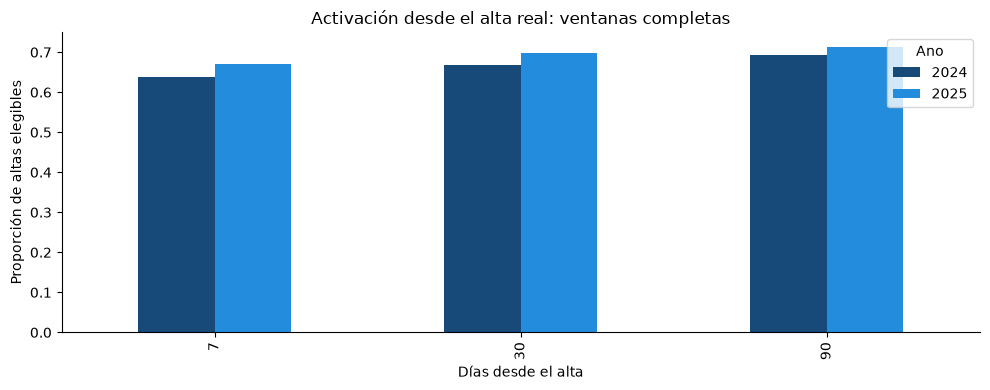

In [22]:
tasas_activacion=[]
for ventana in (7,30,90):
    elegible=(~activacion.IdentidadAmbigua)&activacion.FechaAlta.notna()&(~activacion.CronologiaContradictoria)&(activacion.Cierre-activacion.FechaAlta).dt.days.ge(ventana)
    activacion[f"Elegible{ventana}"]=elegible
    activacion[f"Activa{ventana}"]=activacion.DiasHastaPrimera.between(0,ventana)
    tabla=activacion.loc[elegible].groupby("Ano").agg(Elegibles=("Usuario","size"),Activadas=(f"Activa{ventana}","sum")).reset_index()
    tabla["Ventana"]=ventana; tabla["Tasa"]=tabla.Activadas/tabla.Elegibles
    tasas_activacion.append(tabla)
tasas_activacion=pd.concat(tasas_activacion,ignore_index=True)
display(tasas_activacion)
resultados["activacion"]=tasas_activacion.to_dict("records")
activacion["GrupoEdad"]=pd.cut(activacion.EdadReportada.where(activacion.EdadUtilizable),
    bins=[-1,17,24,34,44,54,64,120],labels=["0–17","18–24","25–34","35–44","45–54","55–64","65–120"])
por_edad=activacion.loc[activacion.Elegible30].groupby(["Ano","GrupoEdad"],observed=True).agg(Elegibles=("Usuario","size"),Activadas=("Activa30","sum"))
por_edad["Tasa"]=por_edad.Activadas/por_edad.Elegibles
display(por_edad)
ax=tasas_activacion.pivot(index="Ventana",columns="Ano",values="Tasa").plot.bar(color=[AZUL,CELESTE])
ax.set(title="Activación desde el alta real: ventanas completas",xlabel="Días desde el alta",ylabel="Proporción de altas elegibles")
plt.tight_layout(); plt.show()

## 10. Calendario y clima: contexto y comparación descriptiva

El calendario distingue feriados nacionales de días no laborables. El calendario considera el traslado de octubre de 2025 al día 10 según la [comunicación oficial de la Resolución 139/2025](https://www.argentina.gob.ar/noticias/el-gobierno-habilito-el-traslado-del-feriado-para-un-nuevo-fin-de-semana-largo). No se considera feriado general un asueto de aplicación sectorial.

El cruce diario interpreta la fecha declarada como referencia local de Buenos Aires. El CSV carece de offset; esta interpretación se conserva como supuesto de cálculo. El clima es un contexto diario para la ciudad, no una medición por estación de bicicletas.

Para explorar lluvia se comparan días con al menos 1 mm contra una mediana de días secos del mismo año, mes y día semanal, excluyendo fechas especiales y exigiendo al menos dos días secos de referencia. Quedan sin referencia las celdas que no cumplen esa condición. Esto controla parcialmente el calendario, sin atribuir causalidad.

In [23]:
clima_fuente=json.loads((RAIZ/"catalogos/clima_diario_era5_fuente.json").read_text(encoding="utf-8"))
clima=pd.DataFrame(clima_fuente["daily"]).rename(columns={"time":"Fecha"})
clima["Fecha"]=pd.to_datetime(clima.Fecha)
calendario=pd.read_csv(RAIZ/"catalogos/calendario_especial_2024_2025.csv",parse_dates=["Fecha"])
assert clima.Fecha.is_unique and calendario.Fecha.is_unique
diario=viajes.loc[observado].groupby("Fecha").size().rename("Registros").reset_index()
assert diario.Fecha.nunique()==len(pd.date_range(diario.Fecha.min(),diario.Fecha.max()))
diario=diario.merge(clima,on="Fecha",how="left",validate="one_to_one").merge(calendario,on="Fecha",how="left",validate="one_to_one")
diario["Tipo"]=diario.Tipo.fillna("Sin fecha especial general")
diario["Ano"]=diario.Fecha.dt.year; diario["Mes"]=diario.Fecha.dt.month; diario["DiaSemana"]=diario.Fecha.dt.dayofweek
campos_clima=["temperature_2m_mean","precipitation_sum","wind_speed_10m_max"]
resultados["contexto"]={"dias":len(diario),"dias_sin_clima":int(diario[campos_clima].isna().any(axis=1).sum()),
    "fechas_especiales":len(calendario),"timezone_clima":clima_fuente["timezone"]}
display(diario.groupby(["Ano","Tipo"]).agg(Dias=("Fecha","size"),MedianaRegistros=("Registros","median")))
display(pd.Series(resultados["contexto"]))

Dias  MedianaRegistros
Ano  Tipo                                              
2024 Día no laborable               1            9927.0
     Feriado nacional              19            4787.0
     Sin fecha especial general   346           10940.0
2025 Día no laborable               4            7067.0
     Feriado nacional              16            4978.0
     Sin fecha especial general   345            8935.0

dias                                            731
dias_sin_clima                                    0
fechas_especiales                                40
timezone_clima       America/Argentina/Buenos_Aires
dtype: object

dias_lluvia_con_referencia                                                       151
mediana_indice_actividad_lluvia                                             0.771526
dias_sin_referencia_suficiente                                                    21
lectura                            Asociación descriptiva. Referencia seca por añ...
dtype: object

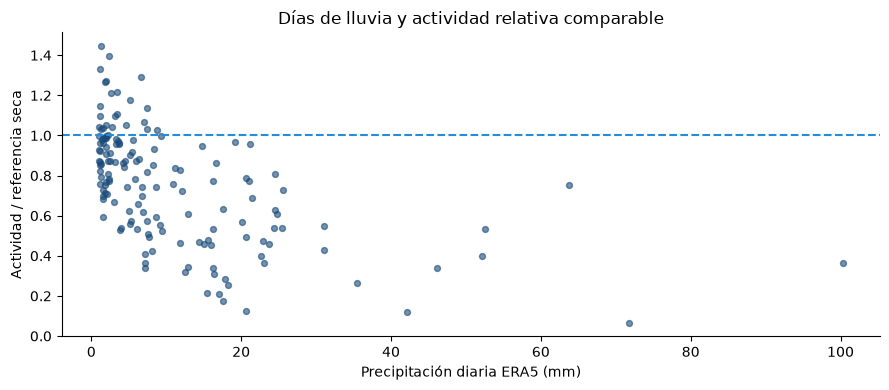

,Fecha,Registros,precipitation_sum,IndiceActividadSeca
596,2025-08-19,726,71.8,0.066563
243,2024-08-31,416,42.1,0.119816
502,2025-05-17,549,20.6,0.127127
501,2025-05-16,1566,17.6,0.174446
530,2025-06-14,571,17.0,0.211325
608,2025-08-31,1088,15.5,0.215488
512,2025-05-27,2722,18.3,0.254857
79,2024-03-20,4024,35.4,0.262355


In [24]:
normal=diario.Tipo.eq("Sin fecha especial general")
seco=normal&diario.precipitation_sum.lt(1)
referencia=diario.loc[seco].groupby(["Ano","Mes","DiaSemana"]).Registros.agg(BaseSeca="median",DiasSecos="size")
diario=diario.join(referencia,on=["Ano","Mes","DiaSemana"],validate="many_to_one")
diario["IndiceActividadSeca"]=diario.Registros/diario.BaseSeca.where(diario.DiasSecos.ge(2))
lluvia=normal&diario.precipitation_sum.ge(1)&diario.IndiceActividadSeca.notna()
resultados["clima_descriptivo"]={"dias_lluvia_con_referencia":int(lluvia.sum()),
    "mediana_indice_actividad_lluvia":float(diario.loc[lluvia,"IndiceActividadSeca"].median()),
    "dias_sin_referencia_suficiente":int(diario.IndiceActividadSeca.isna().sum()),
    "lectura":"Asociación descriptiva. Referencia seca por año/mes/día semanal; fecha declarada interpretada como día local de Buenos Aires."}
display(pd.Series(resultados["clima_descriptivo"]))
fig,ax=plt.subplots(figsize=(9,4))
ax.scatter(diario.loc[lluvia,"precipitation_sum"],diario.loc[lluvia,"IndiceActividadSeca"],s=18,alpha=.6,color=AZUL)
ax.axhline(1,color=CELESTE,linestyle="--")
ax.set(xlabel="Precipitación diaria ERA5 (mm)",ylabel="Actividad / referencia seca",title="Días de lluvia y actividad relativa comparable")
plt.tight_layout(); plt.show()
display(diario.loc[normal&diario.IndiceActividadSeca.notna()].nsmallest(8,"IndiceActividadSeca")[["Fecha","Registros","precipitation_sum","IndiceActividadSeca"]])

## 11. Controles y decisiones para el modelo

Los agregados de movimientos deben conciliar con los registros elegibles y las tasas deben recalcularse desde sus numeradores y denominadores. Se comprueban integridad de fuentes, unicidad, cobertura, ventanas y conservación de conteos. Las excepciones mantienen sus banderas y las ventanas incompletas conservan resultado nulo.

El modelo organiza viajes a su grano, movimientos de estación por fecha/hora y cohortes de usuario con elegibilidad precalculada. Las tablas de movimientos y usuario-año representan granos de decisión distintos. Los catálogos geográficos enriquecidos requieren preparación externa; fecha y categorías simples pueden derivarse mediante DAX.

Los hallazgos y reglas se documentan en `docs/Conclusiones_Exploracion.md`. El contrato de las tablas está en `docs/Modelo_y_Datos.md`.

In [25]:
controles={"FechaInicioCompleta":bool(viajes.Inicio.notna().all()),
    "IdentidadViajeAnoTrasReplica":bool(not viajes.loc[sin_conflicto].duplicated(["Ano","Viaje"]).any()),
    "IdentidadViajeGlobalTrasReplica":bool(not viajes.loc[sin_conflicto].duplicated("Viaje").any()),
    "ConciliacionMovimientos":bool(movimientos.Salidas.sum()==movimientos.Llegadas.sum()==positivo.sum()),
    "CoberturaClimaticaDiaria":bool(not diario[campos_clima].isna().any().any()),
    "CalendarioSinDuplicados":bool(calendario.Fecha.is_unique),
    "TasasEntre0y1":bool(cohortes.Tasa.between(0,1).all()),
    "GranoPerfilEstacion":bool(perfil.index.is_unique and len(perfil)<=2*viajes.Origen.nunique()),
    "ActivacionEntre0y1":bool(tasas_activacion.Tasa.between(0,1).all())}
resultados["controles"]=controles
display(pd.Series(controles))
resultados["modelo_dimensionamiento"]={"viajes_brutos":len(viajes),"usuario_ano":len(usuarios),
    "movimientos_estacion_fecha_hora":len(movimientos),"pares_od_ano":len(flujo),
    "memoria_viajes_mb":round(viajes.memory_usage(deep=True).sum()/1e6,1)}
display(pd.Series(resultados["modelo_dimensionamiento"]))
display(JSON(json.loads(json.dumps(resultados,default=lambda x:x.item() if hasattr(x,"item") else str(x)))))

FechaInicioCompleta                True
IdentidadViajeAnoTrasReplica       True
IdentidadViajeGlobalTrasReplica    True
ConciliacionMovimientos            True
CoberturaClimaticaDiaria           True
CalendarioSinDuplicados            True
TasasEntre0y1                      True
GranoPerfilEstacion                True
ActivacionEntre0y1                 True
dtype: bool

viajes_brutos                      6715466.0
usuario_ano                         547754.0
movimientos_estacion_fecha_hora    3657461.0
pares_od_ano                        185947.0
memoria_viajes_mb                      765.6
dtype: float64

<IPython.core.display.JSON object>